# Text-to-SQL with Open LLMs

**Text-to-SQL** turns a question in natural language ("which country spent the most in 2024?") into a SQL query. Large language models made it practical, and it now powers "chat with your data" features in BI tools and data platforms. This lesson builds a small text-to-SQL system with a free, local open model and, most importantly, **measures** how often it is right.

**After this lesson you can:**

1. Build a prompt that gives an LLM the database schema.
2. Generate, extract and run SQL safely (read-only, time limit, one statement).
3. Evaluate text-to-SQL with **execution accuracy** on a labelled question set.
4. Compare prompting strategies (few-shot examples, self-correction) and analyse the errors.

The model is **Llama 3.2 3B**, served by **Ollama** on your machine (`ollama pull llama3.2:3b`). Larger models are much more accurate; the evaluation method stays the same.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

import json
import numbers
import re
import time
import urllib.request

import numpy as np

OLLAMA = "http://localhost:11434"
MODEL = "llama3.2:3b"

def chat(messages: list[dict], temperature: float = 0.0) -> str:
    body = {"model": MODEL, "messages": messages, "stream": False, "options": {"temperature": temperature, "seed": 0}}
    req = urllib.request.Request(f"{OLLAMA}/api/chat", data=json.dumps(body).encode(), headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=300) as resp:
        return json.load(resp)["message"]["content"]

print("model answer:", chat([{"role": "user", "content": "What is 2 + 3? Answer with the number only."}]))

model answer: 5


## 1. Give the Model the Schema

The model has never seen your database. The prompt must describe the tables, columns, types and keys. The cell builds a compact schema description from the system catalog.

In [2]:
cols = q("""SELECT table_name, column_name, data_type FROM information_schema.columns
            WHERE table_schema = 'public' ORDER BY table_name, ordinal_position""")
fks = q("""SELECT tc.table_name, kcu.column_name, ccu.table_name AS ref_table, ccu.column_name AS ref_column
           FROM information_schema.table_constraints tc
           JOIN information_schema.key_column_usage kcu ON tc.constraint_name = kcu.constraint_name
           JOIN information_schema.constraint_column_usage ccu ON tc.constraint_name = ccu.constraint_name
           WHERE tc.constraint_type = 'FOREIGN KEY'""")
lines = []
for table, part in cols.groupby("table_name"):
    refs = {r.column_name: f"{r.ref_table}.{r.ref_column}" for r in fks[fks.table_name == table].itertuples()}
    short = {"character varying": "varchar", "timestamp without time zone": "timestamp"}
    cols_txt = ", ".join(f"{c} {short.get(t, t)}" + (f" -> {refs[c]}" if c in refs else "")
                         for c, t in zip(part["column_name"], part["data_type"]))
    lines.append(f"{table}({cols_txt})")
SCHEMA = "\n".join(lines)
print(SCHEMA)
print(f"\n~{len(SCHEMA) // 4} tokens")

album(album_id integer, title varchar, artist_id integer -> artist.artist_id)
artist(artist_id integer, name varchar)
customer(customer_id integer, first_name varchar, last_name varchar, company varchar, address varchar, city varchar, state varchar, country varchar, postal_code varchar, phone varchar, fax varchar, email varchar, support_rep_id integer -> employee.employee_id)
employee(employee_id integer, last_name varchar, first_name varchar, title varchar, reports_to integer -> employee.employee_id, birth_date timestamp, hire_date timestamp, address varchar, city varchar, state varchar, country varchar, postal_code varchar, phone varchar, fax varchar, email varchar)
genre(genre_id integer, name varchar)
invoice(invoice_id integer, customer_id integer -> customer.customer_id, invoice_date timestamp, billing_address varchar, billing_city varchar, billing_state varchar, billing_country varchar, billing_postal_code varchar, total numeric)
invoice_line(invoice_line_id integer, invoice_id 

## 2. Generate and Run SQL Safely

Never run model output with full privileges. The guard rails:

1. Accept only **one** `SELECT` (or `WITH`) statement.
2. Run it in a **read-only transaction**, so even a missed `DELETE` fails.
3. Set a **statement timeout**, so a bad cross join cannot block the database.
4. Limit the number of returned rows.

In production, also connect as a role with `SELECT` privileges only (Lesson 16).

In [3]:
SYSTEM = f"""You translate questions into PostgreSQL queries for this database:

{SCHEMA}

Rules: answer with exactly one SQL query in a ```sql code block and nothing else.
Use only the tables and columns above. Revenue is invoice.total, or unit_price * quantity at the invoice_line level."""

def extract_sql(answer: str) -> str:
    m = re.search(r"```(?:sql)?\s*(.*?)(?:```|$)", answer, re.S | re.I)      # the closing fence may be missing
    return (m.group(1) if m else answer).strip().rstrip(";")

def safe_run(sql: str, max_rows: int = 1000) -> pd.DataFrame:
    if not re.match(r"^\s*(select|with)\b", sql, re.I) or ";" in sql:
        raise ValueError("only one SELECT statement is allowed")
    with engine.connect() as conn:
        conn.execute(text("SET TRANSACTION READ ONLY"))
        conn.execute(text("SET LOCAL statement_timeout = '5s'"))
        df = pd.read_sql(text(sql), conn).head(max_rows)
        conn.rollback()
    return df

def ask(question: str, examples: list[dict] | None = None) -> str:
    msgs = [{"role": "system", "content": SYSTEM}]
    for ex in examples or []:
        msgs += [{"role": "user", "content": ex["q"]}, {"role": "assistant", "content": f"```sql\n{ex['sql']}\n```"}]
    msgs.append({"role": "user", "content": question})
    return extract_sql(chat(msgs))

sql = ask("How many tracks are in the Rock genre?")
print(sql)
try:
    print(safe_run(sql))
except Exception as err:                                # model output is not guaranteed to be valid SQL
    print("the generated query was rejected or failed:", str(err).splitlines()[0])

SELECT COUNT(DISTINCT T1.track_id) 
FROM track AS T1 
JOIN genre AS T2 ON T1.genre_id = T2.genre_id 
WHERE T2.name = 'Rock'
   count
0   1297


In [4]:
for bad in ["DELETE FROM invoice", "SELECT 1; DROP TABLE invoice", "WITH x AS (DELETE FROM genre RETURNING *) SELECT * FROM x"]:
    try:
        safe_run(bad)
        print("ran (unexpected):", bad)
    except Exception as err:
        msg = str(getattr(err, "__cause__", None) and err.__cause__.orig or err).splitlines()[0]
        print(f"blocked: {bad[:45]:<45} -> {msg}")

blocked: DELETE FROM invoice                           -> only one SELECT statement is allowed
blocked: SELECT 1; DROP TABLE invoice                  -> only one SELECT statement is allowed
blocked: WITH x AS (DELETE FROM genre RETURNING *) SEL -> cannot execute SELECT in a read-only transaction


The third statement passed the text check (it starts with `WITH`), but the read-only transaction stopped it. Defence in depth: each layer catches what another misses.

## 3. A Labelled Evaluation Set

Text-to-SQL is evaluated with **execution accuracy**: run the generated query and the reference ("gold") query, and compare the **results**, not the SQL text. Two different queries can be equally correct.

The set below has 16 questions of increasing difficulty, each with a gold query written and checked by hand. Benchmarks such as **Spider** and **BIRD** use the same method with thousands of questions.

In [5]:
EVAL = [
    ("How many customers are there?", "SELECT count(*) FROM customer"),
    ("How many tracks are in the Jazz genre?",
     "SELECT count(*) FROM track t JOIN genre g ON g.genre_id = t.genre_id WHERE g.name = 'Jazz'"),
    ("List the names of all media types.", "SELECT name FROM media_type"),
    ("What is the total revenue of all invoices?", "SELECT sum(total) FROM invoice"),
    ("Which country has the most customers?",
     "SELECT country FROM customer GROUP BY country ORDER BY count(*) DESC LIMIT 1"),
    ("How many albums does the artist AC/DC have?",
     "SELECT count(*) FROM album al JOIN artist ar ON ar.artist_id = al.artist_id WHERE ar.name = 'AC/DC'"),
    ("What is the total invoice revenue per billing country? Return country and revenue.",
     "SELECT billing_country, sum(total) FROM invoice GROUP BY billing_country"),
    ("Which 5 customers spent the most? Return first name, last name and total spent.",
     "SELECT c.first_name, c.last_name, sum(i.total) FROM customer c JOIN invoice i ON i.customer_id = c.customer_id "
     "GROUP BY c.customer_id, c.first_name, c.last_name ORDER BY sum(i.total) DESC LIMIT 5"),
    ("What is the average track length in minutes for each genre? Return genre name and average minutes.",
     "SELECT g.name, avg(t.milliseconds) / 60000.0 FROM track t JOIN genre g ON g.genre_id = t.genre_id GROUP BY g.name"),
    ("How many invoices were issued in 2024?",
     "SELECT count(*) FROM invoice WHERE extract(year FROM invoice_date) = 2024"),
    ("Which employee supports the most customers? Return first and last name.",
     "SELECT e.first_name, e.last_name FROM employee e JOIN customer c ON c.support_rep_id = e.employee_id "
     "GROUP BY e.employee_id, e.first_name, e.last_name ORDER BY count(*) DESC LIMIT 1"),
    ("Which genre earned the most revenue from invoice lines?",
     "SELECT g.name FROM invoice_line il JOIN track t ON t.track_id = il.track_id JOIN genre g ON g.genre_id = t.genre_id "
     "GROUP BY g.name ORDER BY sum(il.unit_price * il.quantity) DESC LIMIT 1"),
    ("How many tracks have never been sold?",
     "SELECT count(*) FROM track t WHERE NOT EXISTS (SELECT 1 FROM invoice_line il WHERE il.track_id = t.track_id)"),
    ("List the names of artists that have no albums.",
     "SELECT ar.name FROM artist ar LEFT JOIN album al ON al.artist_id = ar.artist_id WHERE al.album_id IS NULL"),
    ("Which playlist contains the most tracks? Return its name.",
     "SELECT p.name FROM playlist p JOIN playlist_track pt ON pt.playlist_id = p.playlist_id "
     "GROUP BY p.playlist_id, p.name ORDER BY count(*) DESC LIMIT 1"),
    ("What is the total revenue per year? Return year and revenue.",
     "SELECT extract(year FROM invoice_date), sum(total) FROM invoice GROUP BY 1"),
]

def normalise(df: pd.DataFrame) -> list:
    """Order-independent comparison of results: round numbers, ignore column names and row order."""
    rows = []
    for row in df.itertuples(index=False):
        rows.append(tuple(sorted(str(round(float(v), 2)) if isinstance(v, numbers.Number) and not isinstance(v, bool)
                                 else str(v) for v in row)))
    return sorted(rows)

gold = [normalise(safe_run(sql)) for _, sql in EVAL]
print(f"{len(EVAL)} questions; gold answers computed, e.g. {EVAL[4][0]!r} -> {gold[4]}")

16 questions; gold answers computed, e.g. 'Which country has the most customers?' -> [('USA',)]


## 4. Evaluate: Zero-Shot vs Few-Shot vs Self-Correction

Three strategies:

1. **zero-shot**: schema + question.
2. **few-shot**: also three solved example questions (different from the evaluation set) that show the joins and conventions of this database.
3. **few-shot + self-correction**: if the query fails with an error, send the error message back to the model once and ask for a fixed query.

In [6]:
FEW_SHOT = [
    {"q": "How many tracks does the album 'Let There Be Rock' have?",
     "sql": "SELECT count(*) FROM track t JOIN album al ON al.album_id = t.album_id WHERE al.title = 'Let There Be Rock'"},
    {"q": "What is the revenue per customer country from invoice lines?",
     "sql": "SELECT i.billing_country, sum(il.unit_price * il.quantity) FROM invoice_line il "
            "JOIN invoice i ON i.invoice_id = il.invoice_id GROUP BY i.billing_country"},
    {"q": "Which artist has the most tracks? Return the artist name.",
     "sql": "SELECT ar.name FROM track t JOIN album al ON al.album_id = t.album_id JOIN artist ar ON ar.artist_id = al.artist_id "
            "GROUP BY ar.artist_id, ar.name ORDER BY count(*) DESC LIMIT 1"},
]

def evaluate(strategy: str) -> pd.DataFrame:
    records = []
    for (question, _), expected in zip(EVAL, gold):
        t = time.perf_counter()
        sql = ask(question, FEW_SHOT if strategy != "zero-shot" else None)
        status = "wrong result"
        try:
            got = normalise(safe_run(sql))
        except Exception as err:
            got, status = None, "error"
            if strategy == "few-shot + self-correction":
                msg = str(err.__cause__.orig if getattr(err, "__cause__", None) is not None and hasattr(err.__cause__, "orig") else err)
                fix = chat([{"role": "system", "content": SYSTEM},
                            {"role": "user", "content": f"{question}\n\nThis query failed:\n{sql}\nError: {msg.splitlines()[0]}\n"
                                                        "Write a corrected query."}])
                sql = extract_sql(fix)
                try:
                    got, status = normalise(safe_run(sql)), "wrong result"
                except Exception:
                    pass
        if got == expected:
            status = "correct"
        records.append({"strategy": strategy, "question": question, "status": status, "sql": sql,
                        "seconds": time.perf_counter() - t})
    return pd.DataFrame(records)

results = pd.concat([evaluate(s) for s in ["zero-shot", "few-shot", "few-shot + self-correction"]], ignore_index=True)
summary = results.pivot_table(index="strategy", columns="status", values="question", aggfunc="count", fill_value=0)
summary["execution accuracy"] = (summary.get("correct", 0) / len(EVAL)).round(2)
summary = summary.reindex(["zero-shot", "few-shot", "few-shot + self-correction"])
print(f"median time per question: {results['seconds'].median():.1f} s")
summary

median time per question: 5.0 s


status,correct,error,wrong result,execution accuracy
strategy,,,,
zero-shot,12,2,2,0.75
few-shot,14,1,1,0.88
few-shot + self-correction,14,0,2,0.88


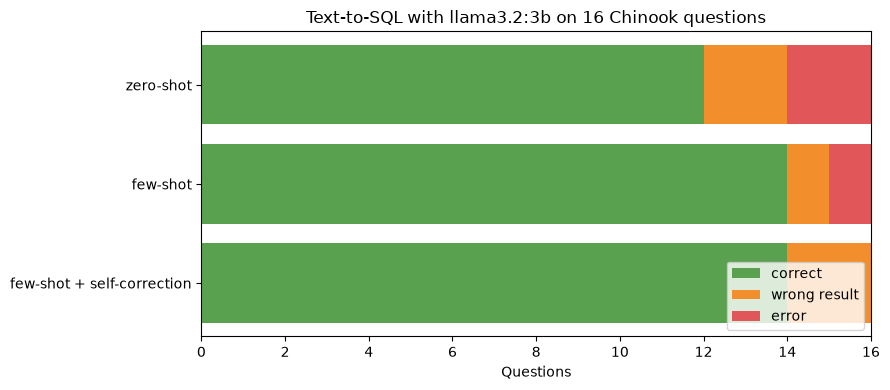

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
order = ["correct", "wrong result", "error"]
colors = {"correct": "#59A14F", "wrong result": "#F28E2B", "error": "#E15759"}
left = np.zeros(len(summary))
for status in order:
    vals = summary[status].values if status in summary else np.zeros(len(summary))
    ax.barh(summary.index, vals, left=left, color=colors[status], label=status)
    left += vals
ax.set(title=f"Text-to-SQL with {MODEL} on {len(EVAL)} Chinook questions", xlabel="Questions")
ax.legend(loc="lower right")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Compare the rows of the table. Few-shot examples help most when the model does not know the conventions of the database. Self-correction can fix only queries that **fail with an error**; it cannot fix a query that runs but answers a different question (a "wrong result"). With 16 questions, one question is 6 percentage points, so small differences between strategies are not meaningful: real evaluations use hundreds of questions.

## 5. Error Analysis

Accuracy alone does not tell you **why** the model fails. Read the failures: the most useful improvements come from patterns (a wrong join path, a misread column, a missing `LIMIT 1`).

In [8]:
best = results[results["strategy"] == "few-shot + self-correction"]
fails = best[best["status"] != "correct"][["question", "status", "sql"]]
pd.set_option("display.max_colwidth", 160)
print(f"{len(fails)} failures of the best strategy")
fails

2 failures of the best strategy


,question,status,sql
40,What is the average track length in minutes for each genre? Return genre name and average minutes.,wrong result,"SELECT g.name, AVG(t.milliseconds / 60000) AS avg_minutes FROM track t JOIN genre g ON g.genre_id = t.genre_id GROUP BY g.name"
44,How many tracks have never been sold?,wrong result,SELECT COUNT(*) \nFROM track t \nWHERE t.track_id NOT IN (\n SELECT pt.track_id \n FROM playlist_track pt \n JOIN playlist p ON p.playlist_id = pt.playli...


Typical failure types of small models:

| Failure | Example | Mitigation |
| :--- | :--- | :--- |
| wrong join path | joins `invoice` to `track` directly | describe foreign keys clearly; few-shot examples with the right joins |
| wrong value format | `WHERE name = 'jazz'` instead of `'Jazz'` | give sample values of categorical columns in the prompt |
| wrong grain | sums `invoice.total` after joining lines (Lesson 05) | state metric definitions in the prompt or a semantic layer |
| integer division | `milliseconds / 60000` drops the fraction in PostgreSQL | say "use 60000.0 for minutes" in the prompt or examples |
| wrong table | uses `playlist_track` for "sold" instead of `invoice_line` | describe what each table means, not only its columns |
| ambiguous question | "top customers" by count or by revenue? | ask the user a clarifying question |

**Ways to improve:**

- **Bigger or code-specialised models** (Qwen2.5-Coder, Llama 3.1 70B, or commercial models) reach much higher accuracy on benchmarks such as BIRD.
- **Schema retrieval:** for databases with hundreds of tables, retrieve only the relevant tables (embeddings, Lesson 14) before prompting.
- **Semantic layers** (dbt metrics, Cube): the model chooses predefined metrics and dimensions instead of writing raw joins.
- **Human review:** show the SQL and the result to the user, with the option to correct it.

*Insight: Treat text-to-SQL as a system, not a prompt: give the model a precise schema and examples, run its SQL in a read-only sandbox, and measure execution accuracy on a labelled question set from your own database before you trust it with real decisions.*

## Real-World Use Case or Analogy

Text-to-SQL is like a **new junior analyst** who knows SQL well but not your company's database. On the first day, they need a map of the tables (the schema), a few solved examples (few-shot), and a supervisor who checks their numbers (evaluation). You would not give them permission to delete data (read-only role).

BI tools (Power BI Copilot, Looker, Databricks Genie, Snowflake Cortex Analyst) offer text-to-SQL today. The companies that succeed with it invest in clean schemas, documented metrics and evaluation sets — the same steps as this lesson.